# Jobsheet 03 — Teknik Regresi Gambar
---


> Khumaira Yuliazzara (3.34.24.9.04)

## Praktikum D1 — Regresi dari Citra Sintetis (Radius Lingkaran)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras import layers, models

def make_sample(img_size=64, min_r=5, max_r=20):
    r = np.random.randint(min_r, max_r + 1)
    img = np.zeros((img_size, img_size), dtype=np.uint8)
    cx = np.random.randint(r, img_size - r)
    cy = np.random.randint(r, img_size - r)
    cv2.circle(img, (cx, cy), r, (255,), -1)
    img = (img / 255.0).astype(np.float32)
    img3 = np.stack([img, img, img], axis=-1)
    return img3, float(r), (cx, cy)

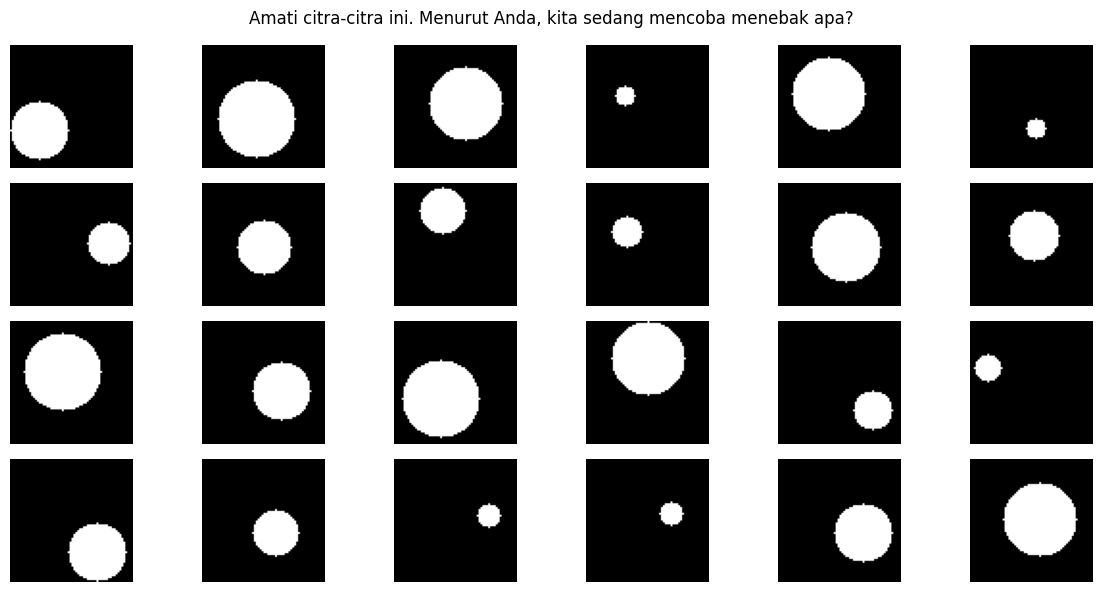

In [ ]:
N_show = 24
samples = [make_sample() for _ in range(N_show)]
imgs = [s[0] for s in samples]
rads = [s[1] for s in samples]
centers = [s[2] for s in samples]

cols = 6
rows = N_show // cols
plt.figure(figsize=(12, 6))
for i in range(N_show):
    plt.subplot(rows, cols, i+1)
    plt.imshow(imgs[i].squeeze(), cmap='gray')
    plt.axis('off')
plt.suptitle("Amati citra-citra ini. Menurut Anda, kita sedang mencoba menebak apa?")
plt.tight_layout()
plt.show()

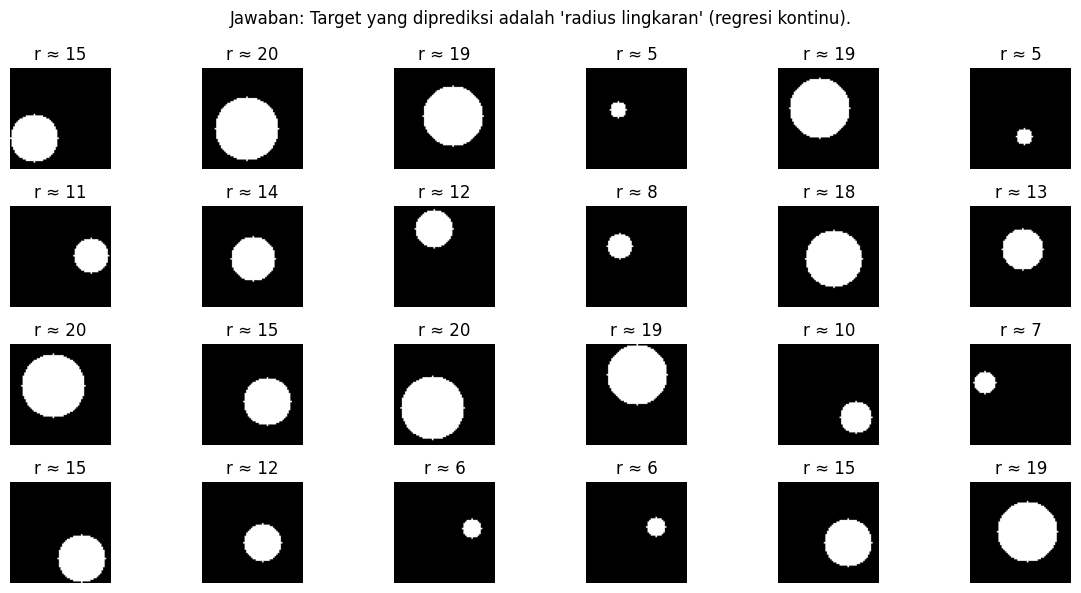

In [ ]:
plt.figure(figsize=(12, 6))
for i in range(N_show):
    plt.subplot(rows, cols, i+1)
    plt.imshow(imgs[i].squeeze(), cmap='gray')
    plt.title(f"r ≈ {int(rads[i])}")
    plt.axis('off')
plt.suptitle("Jawaban: Target yang diprediksi adalah 'radius lingkaran' (regresi kontinu).")
plt.tight_layout()
plt.show()

In [ ]:
N = 3000
X, y, C = zip(*[make_sample() for _ in range(N)])
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

model_d1 = models.Sequential([
    layers.Input((64,64,3)),
    layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'), layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1)
])
model_d1.compile(optimizer='adam', loss='mse', metrics=['mae'])
history_d1 = model_d1.fit(Xtr, ytr, validation_data=(Xte, yte), epochs=12, batch_size=64, verbose=0)

y_pred_d1 = model_d1.predict(Xte).ravel()
mae = mean_absolute_error(yte, y_pred_d1)
rmse = float(np.sqrt(np.mean((yte - y_pred_d1)**2)))
r2 = r2_score(yte, y_pred_d1)
print(f"MAE={mae:.3f} | RMSE={rmse:.3f} | R²={r2:.3f}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step
MAE=1.004 | RMSE=1.207 | R²=0.932


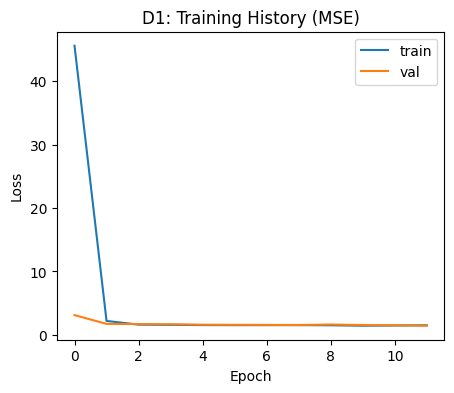

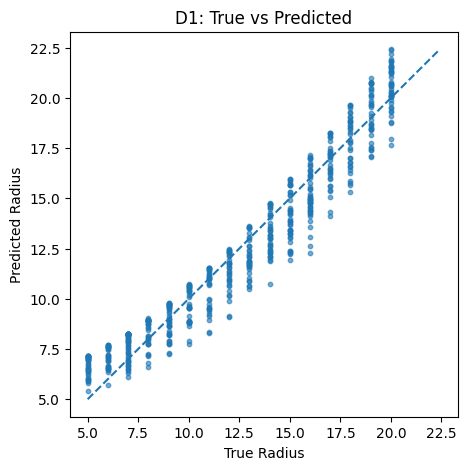

In [ ]:
plt.figure(figsize=(5,4))
plt.plot(history_d1.history['loss'], label='train')
plt.plot(history_d1.history['val_loss'], label='val')
plt.title("D1: Training History (MSE)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()

plt.figure(figsize=(5,5))
plt.scatter(yte, y_pred_d1, s=10, alpha=0.6)
lims = [min(yte.min(), y_pred_d1.min()), max(yte.max(), y_pred_d1.max())]
plt.plot(lims, lims, '--')
plt.xlabel("True Radius"); plt.ylabel("Predicted Radius")
plt.title("D1: True vs Predicted")
plt.show()

## Persiapan Kaggle

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"khumairayul","key":"ae5293d546f69c5ab9c8691e2eabacb1"}'}

In [ ]:
import os, shutil
if os.path.exists("kaggle.json"):
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    shutil.copy("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    print("Kaggle API siap digunakan.")
else:
    print("kaggle.json belum ditemukan. Upload terlebih dahulu.")

Kaggle API siap digunakan.


In [ ]:
!pip -q install kaggle

## Praktikum D2 — Menebak Umur dari Foto Wajah (UTKFace)

In [ ]:
!kaggle datasets download -d jangedoo/utkface-new -p /content -q
!unzip -q /content/utkface-new.zip -d /content/utk
print("Dataset UTKFace berhasil diekstrak.")

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors
Dataset UTKFace berhasil diekstrak.


Total gambar ditemukan: 66966


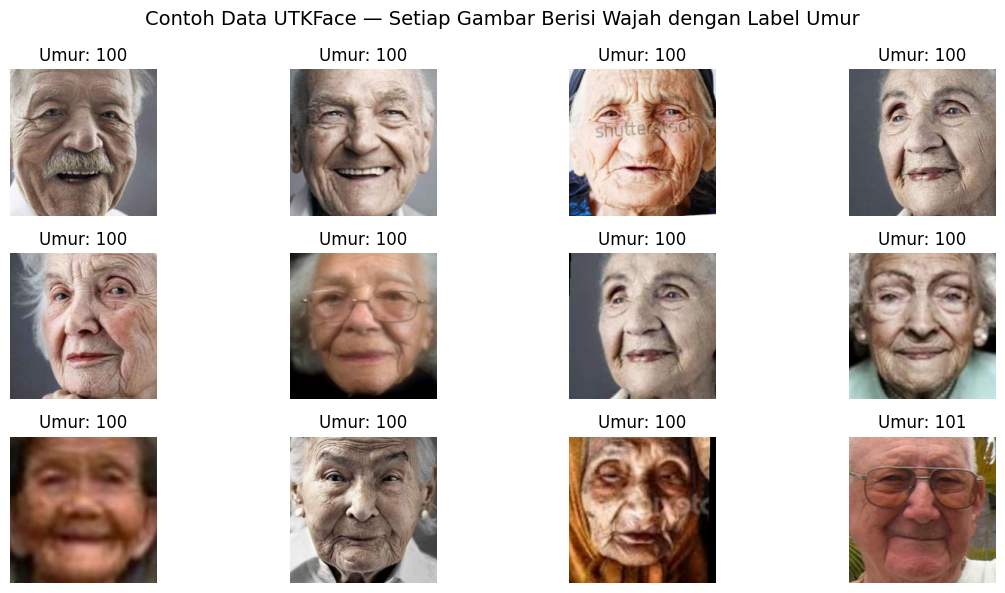

In [ ]:
import glob
from PIL import Image

files_all = sorted(glob.glob("/content/utk/**/*.jpg", recursive=True))
files_utk = [f for f in files_all if os.path.basename(f).split("_")[0].isdigit() and len(os.path.basename(f).split("_")) >= 4]
print(f"Total gambar ditemukan: {len(files_utk)}")

plt.figure(figsize=(12, 6))
for i, f in enumerate(files_utk[:12]):
    age = int(os.path.basename(f).split("_")[0])
    img = Image.open(f)
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f"Umur: {age}")
    plt.axis("off")
plt.suptitle("Contoh Data UTKFace — Setiap Gambar Berisi Wajah dengan Label Umur", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
def parse_age_from_name(fp):
    return int(os.path.basename(fp).split('_')[0])

ages = np.array([parse_age_from_name(f) for f in files_utk], dtype=np.float32)
train_files, test_files, y_train, y_test = train_test_split(files_utk, ages, test_size=0.2, random_state=42)

IMG_AGE = 160

def load_img_age(fp, label):
    img = tf.io.read_file(fp)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_AGE, IMG_AGE))
    return img / 255.0, label

train_ds_age = tf.data.Dataset.from_tensor_slices((train_files, y_train)).map(load_img_age).batch(64)
test_ds_age = tf.data.Dataset.from_tensor_slices((test_files, y_test)).map(load_img_age).batch(64)
print("Dataset siap dilatih.")

Dataset siap dilatih.


In [ ]:
print("Hardware:", "GPU" if tf.config.list_physical_devices('GPU') else "CPU")

base_age = tf.keras.applications.MobileNetV2(include_top=False, input_shape=(IMG_AGE, IMG_AGE, 3), weights='imagenet')
base_age.trainable = False

inputs = tf.keras.Input(shape=(IMG_AGE, IMG_AGE, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)
x = base_age(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(128, activation='relu')(x)
outputs = layers.Dense(1)(x)
model_age = tf.keras.Model(inputs, outputs)

model_age.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse', metrics=['mae'])
model_age.summary()

Hardware: GPU
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
838/838 ━━━━━━━━━━━━━━━━━━━━ 56s 53ms/step - loss: 181.5742 - mae: 9.9210 - val_loss: 146.1314 - val_mae: 9.0808 - learning_rate: 0.0010
Epoch 2/10
838/838 ━━━━━━━━━━━━━━━━━━━━ 35s 42ms/step - loss: 143.0230 - mae: 8.7541 - val_loss: 136.3669 - val_mae: 8.7730 - learning_rate: 0.0010
Epoch 3/10
838/838 ━━━━━━━━━━━━━━━━━━━━ 50s 53ms/step - loss: 135.6302 - mae: 8.5110 - val_loss: 125.1036 - val_mae: 8.3648 - learning_rate: 0.0010
Epoch 4/10
838/838 ━━━━━━━━━━━━━━━━━━━━ 71s 40ms/step - loss: 129.1665 - mae: 8.3212 - val_loss: 117.1253 - val_mae: 8.0787 - learning_rate: 0.0010
Epoch 5/10
838/838 ━━━━━━━━━━━━━━━━━━━━ 45s 44ms/step - loss: 123.7649 - mae: 8.1573 - val_loss: 111.1367 - val_mae: 7.8223 - learning_rate: 0.0010
Epoch 6/10
838/838 ━━━━━━━━━━━━━━━━━━━━ 38s 41ms/step - loss: 118.7311 - mae: 8.0002 - val_loss: 109.7511 - val_mae: 7.8248 - learning_rate: 0.0010
Epoch 7/10
838/838 ━━━━━━━━━━━━━━━━━━━━ 40s 39ms/step - loss: 115.8781 - mae: 7.9103 - val_loss: 109.7670 - val_

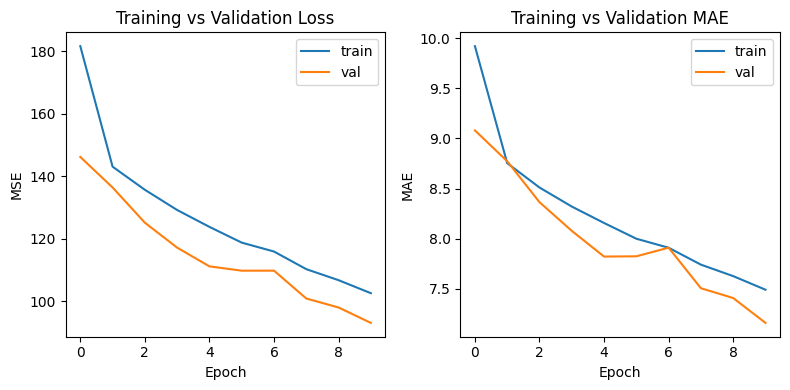

In [ ]:
cb_age = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor='val_loss'),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5, min_lr=1e-5, monitor='val_loss')
]

history_age = model_age.fit(train_ds_age, validation_data=test_ds_age, epochs=10, callbacks=cb_age, verbose=1)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(history_age.history['loss'], label='train')
plt.plot(history_age.history['val_loss'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Training vs Validation Loss')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history_age.history['mae'], label='train')
plt.plot(history_age.history['val_mae'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MAE')
plt.title('Training vs Validation MAE')
plt.legend()
plt.tight_layout()
plt.show()

Epoch 1/5
838/838 ━━━━━━━━━━━━━━━━━━━━ 70s 63ms/step - loss: 104.8373 - mae: 7.4442 - val_loss: 182.6047 - val_mae: 10.3996 - learning_rate: 1.0000e-04
Epoch 2/5
838/838 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - loss: 43.7915 - mae: 4.9252 - val_loss: 54.0513 - val_mae: 5.6370 - learning_rate: 1.0000e-04
Epoch 3/5
838/838 ━━━━━━━━━━━━━━━━━━━━ 38s 45ms/step - loss: 29.4368 - mae: 4.0367 - val_loss: 32.7191 - val_mae: 4.2040 - learning_rate: 1.0000e-04
Epoch 4/5
838/838 ━━━━━━━━━━━━━━━━━━━━ 38s 45ms/step - loss: 20.5047 - mae: 3.3939 - val_loss: 28.1060 - val_mae: 3.8210 - learning_rate: 1.0000e-04
Epoch 5/5
838/838 ━━━━━━━━━━━━━━━━━━━━ 44s 50ms/step - loss: 16.1873 - mae: 3.0051 - val_loss: 25.9367 - val_mae: 3.5648 - learning_rate: 1.0000e-04


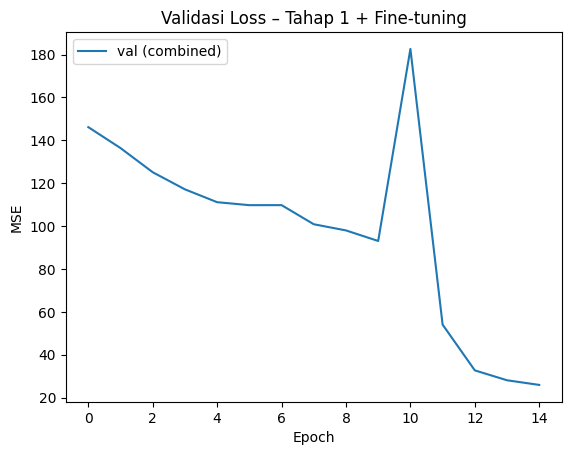

In [ ]:
base_age.trainable = True
for layer in base_age.layers[:-30]:
    layer.trainable = False

model_age.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss='mse', metrics=['mae'])

history_age_ft = model_age.fit(train_ds_age, validation_data=test_ds_age, epochs=5, callbacks=cb_age, verbose=1)

plt.plot(history_age.history['val_loss'] + history_age_ft.history['val_loss'], label='val (combined)')
plt.title("Validasi Loss – Tahap 1 + Fine-tuning")
plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.legend(); plt.show()

MAE = 3.56 tahun
RMSE = 5.09 tahun
R² = 0.944


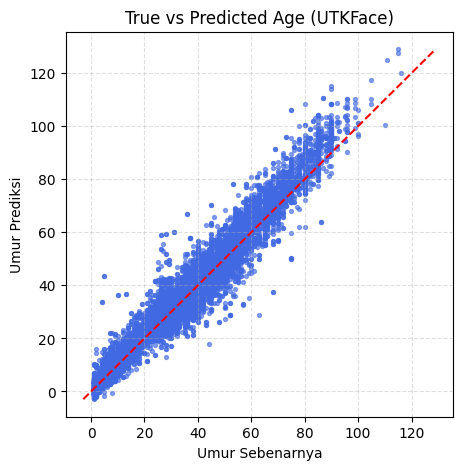

In [ ]:
from math import sqrt

y_pred_age = np.concatenate([model_age.predict(batch[0], verbose=0).ravel() for batch in test_ds_age])
mae_age = mean_absolute_error(y_test, y_pred_age)
rmse_age = sqrt(np.mean((y_test - y_pred_age)**2))
r2_age = r2_score(y_test, y_pred_age)
print(f"MAE = {mae_age:.2f} tahun")
print(f"RMSE = {rmse_age:.2f} tahun")
print(f"R² = {r2_age:.3f}")

plt.figure(figsize=(5,5))
plt.scatter(y_test, y_pred_age, s=8, alpha=0.6, color='royalblue')
lims = [min(y_test.min(), y_pred_age.min()), max(y_test.max(), y_pred_age.max())]
plt.plot(lims, lims, '--', color='red')
plt.xlabel("Umur Sebenarnya")
plt.ylabel("Umur Prediksi")
plt.title("True vs Predicted Age (UTKFace)")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

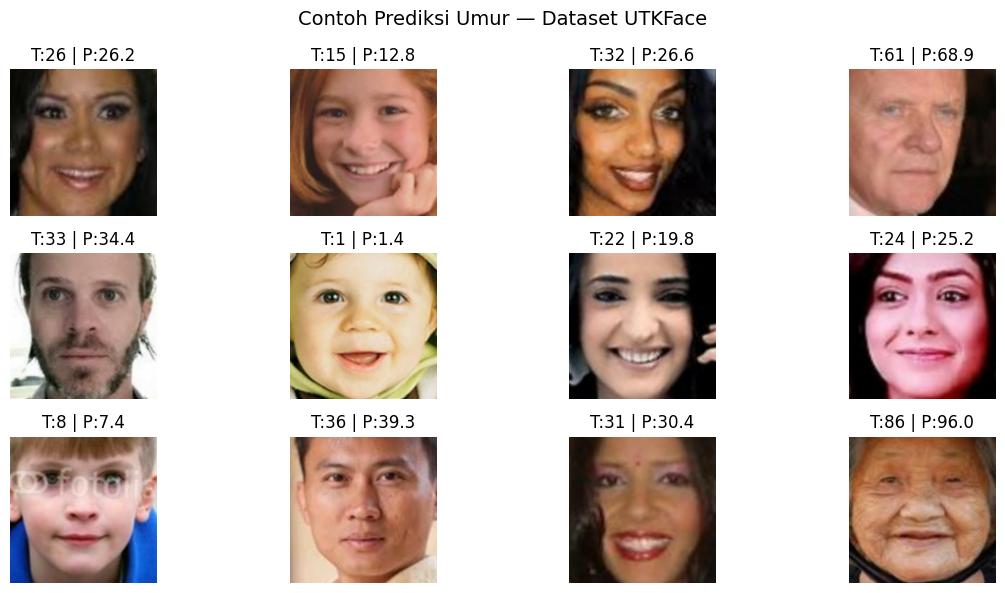

In [ ]:
import random

sample_paths = random.sample(test_files, 12)

plt.figure(figsize=(12,6))
for i, path in enumerate(sample_paths):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_AGE, IMG_AGE))/255.0
    true_age = int(os.path.basename(path).split('_')[0])
    pred_age = model_age.predict(tf.expand_dims(img, 0), verbose=0).ravel()[0]
    plt.subplot(3,4,i+1)
    plt.imshow(img.numpy())
    plt.title(f"T:{true_age} | P:{pred_age:.1f}")
    plt.axis('off')
plt.suptitle("Contoh Prediksi Umur — Dataset UTKFace", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
group_edges = [0, 10, 20, 30, 40, 50, 60, 70, 80, 120]
abs_err = np.abs(y_test - y_pred_age)
for lo, hi in zip(group_edges[:-1], group_edges[1:]):
    mask = (y_test > lo) & (y_test <= hi) if lo > 0 else (y_test <= hi)
    if mask.sum() > 0:
        print(f"Umur {lo}-{hi}: n={mask.sum():5d} | MAE={abs_err[mask].mean():.2f}")

Umur 0-10: n= 2552 | MAE=1.74
Umur 10-20: n= 1162 | MAE=3.01
Umur 20-30: n= 3734 | MAE=2.85
Umur 30-40: n= 2084 | MAE=4.06
Umur 40-50: n= 1087 | MAE=4.85
Umur 50-60: n= 1289 | MAE=4.95
Umur 60-70: n=  712 | MAE=5.48
Umur 70-80: n=  422 | MAE=6.31
Umur 80-120: n=  352 | MAE=7.06


Saving Mera.jpeg to Mera.jpeg


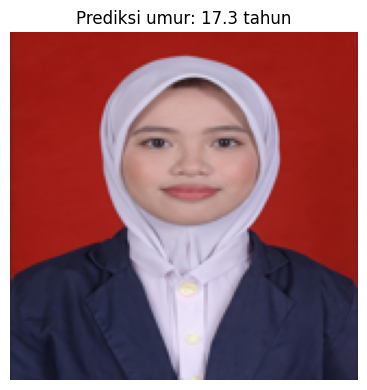

In [ ]:
up_age = files.upload()
names_age = list(up_age.keys())
plt.figure(figsize=(4*len(names_age), 4))
for i, name in enumerate(names_age):
    im = Image.open(name).convert("RGB").resize((IMG_AGE, IMG_AGE))
    arr = np.array(im, dtype=np.float32) / 255.0
    pred = model_age.predict(arr[None], verbose=0).ravel()[0]
    plt.subplot(1, len(names_age), i+1)
    plt.imshow(im)
    plt.title(f"Prediksi umur: {pred:.1f} tahun")
    plt.axis('off')
plt.tight_layout()
plt.show()

## Praktikum D3 — Prediksi Pawpularity Foto Hewan

In [ ]:
!kaggle competitions download -c petfinder-pawpularity-score -p /content -q
!unzip -q /content/petfinder-pawpularity-score.zip -d /content/paw
print("Dataset Pawpularity berhasil diekstrak.")

Dataset Pawpularity berhasil diekstrak.


                                 Id  Subject Focus  Eyes  Face  Near  Action  \
0  0007de18844b0dbbb5e1f607da0606e0              0     1     1     1       0   
1  0009c66b9439883ba2750fb825e1d7db              0     1     1     0       0   
2  0013fd999caf9a3efe1352ca1b0d937e              0     1     1     1       0   
3  0018df346ac9c1d8413cfcc888ca8246              0     1     1     1       0   
4  001dc955e10590d3ca4673f034feeef2              0     0     0     1       0   

   Accessory  Group  Collage  Human  Occlusion  Info  Blur  Pawpularity  \
0          0      1        0      0          0     0     0           63   
1          0      0        0      0          0     0     0           42   
2          0      0        0      1          1     0     0           28   
3          0      0        0      0          0     0     0           15   
4          0      1        0      0          0     0     0           72   

                                                path  
0  /content/p

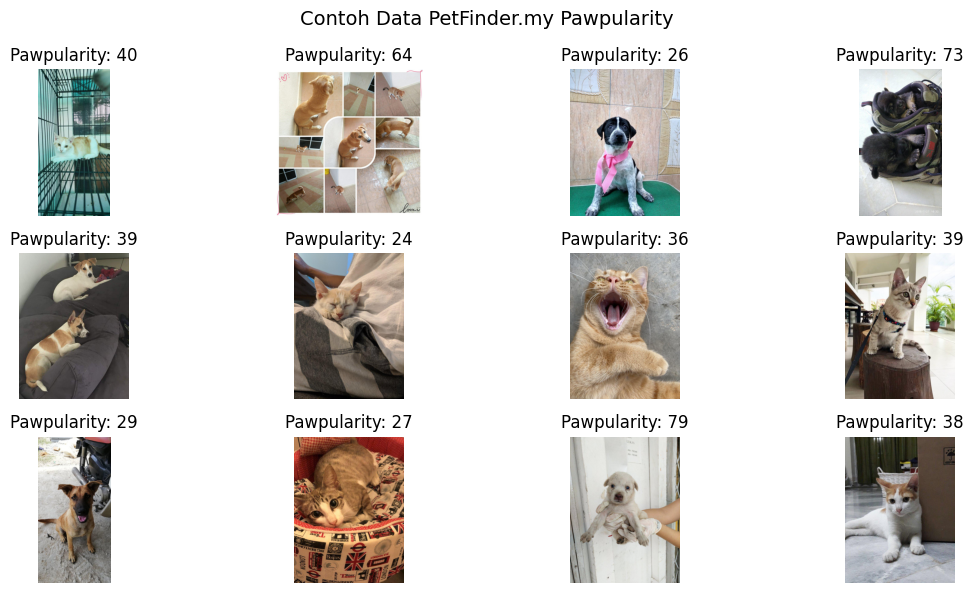

In [ ]:
import pandas as pd

df = pd.read_csv('/content/paw/train.csv')
df['path'] = df['Id'].apply(lambda x: f"/content/paw/train/{x}.jpg")
print(df.head())

plt.figure(figsize=(12, 6))
for i, row in enumerate(df.sample(12, random_state=42).itertuples()):
    img = Image.open(row.path)
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f"Pawpularity: {row.Pawpularity}")
    plt.axis('off')
plt.suptitle("Contoh Data PetFinder.my Pawpularity", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
IMG_PAW = 224
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)

def load_image_paw(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_PAW, IMG_PAW))
    img = tf.cast(img, tf.float32) / 255.0
    return img, tf.cast(label, tf.float32)

train_ds_paw = tf.data.Dataset.from_tensor_slices((train_df['path'].values, train_df['Pawpularity'].values)).map(load_image_paw, num_parallel_calls=tf.data.AUTOTUNE).shuffle(4096).batch(64).prefetch(tf.data.AUTOTUNE)
val_ds_paw = tf.data.Dataset.from_tensor_slices((val_df['path'].values, val_df['Pawpularity'].values)).map(load_image_paw, num_parallel_calls=tf.data.AUTOTUNE).batch(64).prefetch(tf.data.AUTOTUNE)

print(f"Dataset siap digunakan — {len(train_df)} untuk training, {len(val_df)} untuk validasi.")

Dataset siap digunakan — 7929 untuk training, 1983 untuk validasi.


In [ ]:
base_paw = tf.keras.applications.EfficientNetB0(include_top=False, input_shape=(IMG_PAW, IMG_PAW, 3), weights='imagenet')
base_paw.trainable = False

inputs = tf.keras.Input((IMG_PAW, IMG_PAW, 3))
x = tf.keras.applications.efficientnet.preprocess_input(inputs * 255.0)
x = base_paw(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation='relu')(x)
outputs = layers.Dense(1)(x)
model_paw = tf.keras.Model(inputs, outputs)

model_paw.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_paw.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_1 (Multiply)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
cb_paw = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5)
]
history_paw = model_paw.fit(train_ds_paw, validation_data=val_ds_paw, epochs=10, callbacks=cb_paw, verbose=1)

Epoch 1/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 98s 442ms/step - loss: 598.3439 - mae: 17.9678 - val_loss: 475.7875 - val_mae: 15.9990 - learning_rate: 0.0010
Epoch 2/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 37s 204ms/step - loss: 425.0970 - mae: 15.2236 - val_loss: 429.7785 - val_mae: 15.3510 - learning_rate: 0.0010
Epoch 3/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 39s 222ms/step - loss: 391.7764 - mae: 14.6374 - val_loss: 408.4852 - val_mae: 15.0396 - learning_rate: 0.0010
Epoch 4/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 40s 231ms/step - loss: 376.3698 - mae: 14.3989 - val_loss: 391.2681 - val_mae: 14.4975 - learning_rate: 0.0010
Epoch 5/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 43s 225ms/step - loss: 360.9100 - mae: 14.0931 - val_loss: 383.1751 - val_mae: 14.4307 - learning_rate: 0.0010
Epoch 6/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 39s 226ms/step - loss: 349.9505 - mae: 13.9203 - val_loss: 377.3448 - val_mae: 14.4457 - learning_rate: 0.0010
Epoch 7/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 35s 183ms/step - loss: 343.9555 - mae: 13.7991 - val_l

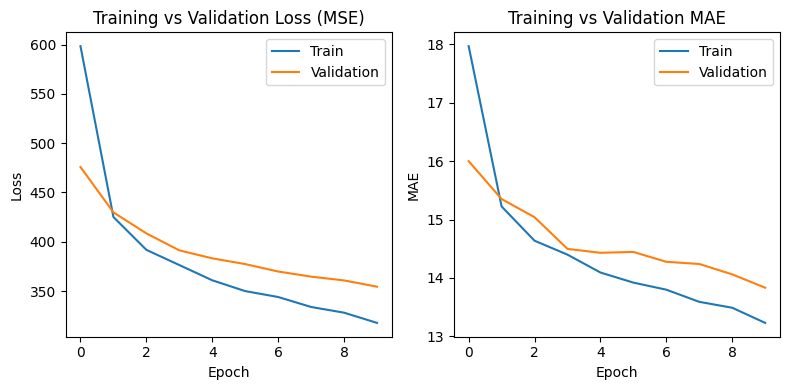

In [ ]:
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(history_paw.history['loss'], label='Train')
plt.plot(history_paw.history['val_loss'], label='Validation')
plt.title("Training vs Validation Loss (MSE)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.subplot(1,2,2)
plt.plot(history_paw.history['mae'], label='Train')
plt.plot(history_paw.history['val_mae'], label='Validation')
plt.title("Training vs Validation MAE")
plt.xlabel("Epoch"); plt.ylabel("MAE"); plt.legend()
plt.tight_layout()
plt.show()

MAE = 13.83
RMSE = 18.83
R² = 0.198


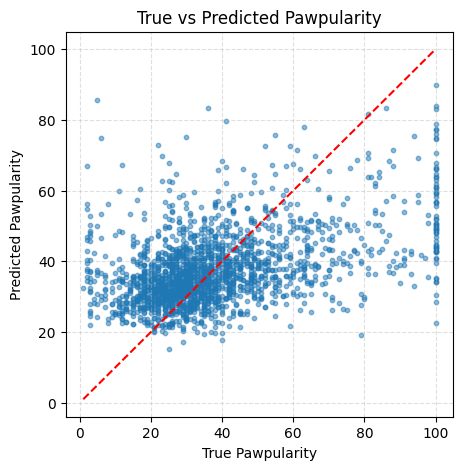

In [ ]:
y_true_paw = val_df['Pawpularity'].values.astype(np.float32)
y_pred_paw = np.concatenate([model_paw.predict(batch[0], verbose=0).ravel() for batch in val_ds_paw])

mae_paw = mean_absolute_error(y_true_paw, y_pred_paw)
rmse_paw = sqrt(np.mean((y_true_paw - y_pred_paw)**2))
r2_paw = r2_score(y_true_paw, y_pred_paw)
print(f"MAE = {mae_paw:.2f}")
print(f"RMSE = {rmse_paw:.2f}")
print(f"R² = {r2_paw:.3f}")

plt.figure(figsize=(5,5))
plt.scatter(y_true_paw, y_pred_paw, s=10, alpha=0.5)
lims = [min(y_true_paw.min(), y_pred_paw.min()), max(y_true_paw.max(), y_pred_paw.max())]
plt.plot(lims, lims, '--', color='red')
plt.xlabel("True Pawpularity")
plt.ylabel("Predicted Pawpularity")
plt.title("True vs Predicted Pawpularity")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

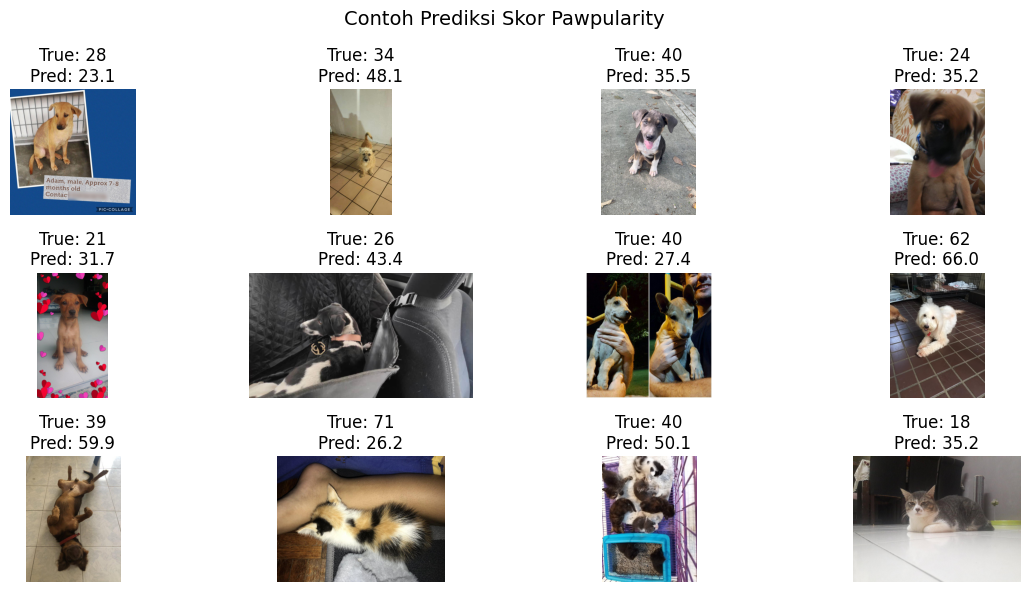

In [ ]:
sample_rows = val_df.sample(12, random_state=1)

plt.figure(figsize=(12,6))
for i, row in enumerate(sample_rows.itertuples()):
    img = Image.open(row.path)
    pred = model_paw.predict(tf.expand_dims(load_image_paw(row.path, row.Pawpularity)[0], 0), verbose=0).ravel()[0]
    plt.subplot(3,4,i+1)
    plt.imshow(img)
    plt.title(f"True: {row.Pawpularity}\nPred: {pred:.1f}")
    plt.axis('off')
plt.suptitle("Contoh Prediksi Skor Pawpularity", fontsize=14)
plt.tight_layout()
plt.show()

Saving 1792138194199.jpg to 1792138194199.jpg


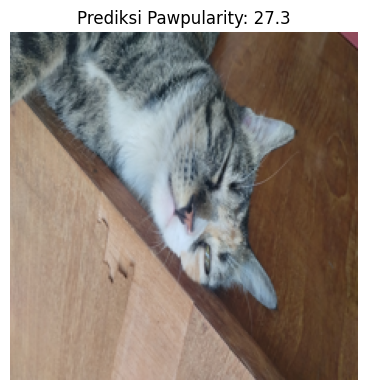

In [ ]:
up_paw = files.upload()
names_paw = list(up_paw.keys())
plt.figure(figsize=(4*len(names_paw), 4))
for i, name in enumerate(names_paw):
    im = Image.open(name).convert("RGB").resize((IMG_PAW, IMG_PAW))
    arr = np.array(im, dtype=np.float32) / 255.0
    pred = model_paw.predict(arr[None], verbose=0).ravel()[0]
    plt.subplot(1, len(names_paw), i+1)
    plt.imshow(im)
    plt.title(f"Prediksi Pawpularity: {pred:.1f}")
    plt.axis('off')
plt.tight_layout()
plt.show()

### Percobaan 2

Saving 1792135769687.webp to 1792135769687.webp


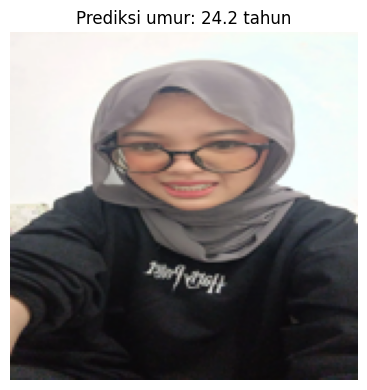

In [ ]:
up_age = files.upload()
names_age = list(up_age.keys())
plt.figure(figsize=(4*len(names_age), 4))
for i, name in enumerate(names_age):
    im = Image.open(name).convert("RGB").resize((IMG_AGE, IMG_AGE))
    arr = np.array(im, dtype=np.float32) / 255.0
    pred = model_age.predict(arr[None], verbose=0).ravel()[0]
    plt.subplot(1, len(names_age), i+1)
    plt.imshow(im)
    plt.title(f"Prediksi umur: {pred:.1f} tahun")
    plt.axis('off')
plt.tight_layout()
plt.show()